<a href="https://colab.research.google.com/github/gemmamico/pork-rasher-defects/blob/main/notebooks/pork_rasher_defects.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pork rasher packaging defects

This notebook trains two AI models to detect packaging defects in pork rasher tray photos, then tests how accurate and fast they are.

**What it does**
1. Downloads the tray photos from Roboflow.
2. Checks the labels to make sure the data looks right before training.
3. Checks whether photos from the same video end up in both the training and test sets.
4. Trains two models - a small fast one and a slightly bigger one.
5. Tests both on photos they haven't seen before and compares the results.
6. Runs the code tests and saves the documentation.

**How to run it**
1. Runtime - Change runtime type - T4 GPU - Save.
2. Put your GitHub username in the Settings cell below.
3. Runtime - Run all.
4. Paste your Roboflow API key when the box appears.

It takes about an hour. Leave this tab open.

## 1. Settings

This is the only cell that needs editing. Each number is a choice I made for the project - I explain them in my report.

In [1]:
GITHUB_USER = "gemmamico"
REPO_NAME = "pork-rasher-defects"

DATASET_VERSION = 4    # Roboflow dataset version described in the unit's dataset slides
EPOCHS = 15            # maximum number of passes through the training images
PATIENCE = 5           # early stopping: stop if validation accuracy hasn't improved for 8 epochs
IMG_SIZE = 640         # images are resized to 640 px on their long side before entering the model
SEED = 0               # fixed random seed so the run can be repeated
TRAYS_PER_MINUTE = 60  # ASSUMED production-line speed: state and justify this in your report
N_TIMING_IMAGES = 30   # number of test images used for the speed test

# The two models being compared. Both were pre-trained on the COCO photo dataset
# and are fine-tuned here on the tray images.
MODELS = {
    "baseline": "yolov8n.pt",  # YOLOv8 nano: the smallest and fastest
    "main": "yolov8s.pt",      # YOLOv8 small: more parameters, usually more accurate but slower
}

## 2. Setup

Checks the GPU is on, downloads my code from GitHub, and installs the required libraries.

In [2]:
import os
import shutil
import subprocess
import sys
import time
from pathlib import Path

import torch

if not torch.cuda.is_available():
    raise RuntimeError(
        "No GPU found. Go to Runtime > Change runtime type > T4 GPU, then Runtime > Run all again."
    )
print("GPU:", torch.cuda.get_device_name(0))

REPO_DIR = Path(f"/content/{REPO_NAME}")
if REPO_DIR.is_dir():  # already downloaded earlier in this session: fetch any updates
    git = subprocess.run(["git", "-C", str(REPO_DIR), "pull", "-q"], capture_output=True, text=True)
else:
    git = subprocess.run(
        ["git", "clone", "-q", f"https://github.com/{GITHUB_USER}/{REPO_NAME}.git", str(REPO_DIR)],
        capture_output=True,
        text=True,
    )
if git.returncode != 0:
    raise RuntimeError(
        "Couldn't download your repo. Check GITHUB_USER and REPO_NAME in the Settings cell, "
        "and make sure the repo is Public.\n" + git.stderr
    )

# Find the code, even if it was uploaded inside an extra folder by mistake.
found = list(REPO_DIR.glob("**/requirements.txt"))
if not found:
    raise RuntimeError("requirements.txt isn't in your repo yet. Upload all the starter files, then run this again.")
CODE_DIR = min(found, key=lambda path: len(path.parts)).parent
if CODE_DIR != REPO_DIR:
    print("Note: your files are inside an extra folder on GitHub. That's OK, the notebook still works.")

subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-r", str(CODE_DIR / "requirements.txt")], check=True)

sys.path.insert(0, str(CODE_DIR / "src"))
import pork_inspect as pi

RESULTS = CODE_DIR / "results"
DOCS = CODE_DIR / "docs"
RESULTS.mkdir(exist_ok=True)
DOCS.mkdir(exist_ok=True)
print("Ready. Your code is in", CODE_DIR)

GPU: Tesla T4
Ready. Your code is in /content/pork-rasher-defects


## 3. Download the dataset

To find your Roboflow API key: sign in at roboflow.com, go to Settings, then API Keys, and copy the Private API Key.

Paste it into the box below. It stays hidden and is not saved in this notebook.

In [3]:
from getpass import getpass

from roboflow import Roboflow

rf = Roboflow(api_key=getpass("Paste your Roboflow API key, then press Enter: "))
project = rf.workspace("hello-2aqe0").project("pork-rasher-error-packaging")
dataset = project.version(DATASET_VERSION).download("yolov8", location="/content/data")

DATA_DIR = dataset.location
DATA_YAML = pi.fix_data_yaml(DATA_DIR)
CLASS_NAMES = pi.read_class_names(DATA_YAML)
print("Dataset folder:", DATA_DIR)
print("Classes:", CLASS_NAMES)

Paste your Roboflow API key, then press Enter: ··········
loading Roboflow workspace...
loading Roboflow project...



Extracting Dataset Version Zip to /content/data in yolov8:: 100%|██████████| 7103/7103 [00:01<00:00, 5512.04it/s]

Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
Dataset folder: /content/data
Classes: ['loose-meat', 'packaging-error', 'twisted-meat', 'unsealed', 'wrinkle']


## 4. Check the labels

Before training, I want to know how many labelled boxes there are for each defect type across the three splits (training, validation and test).

Things to look for:
- defect types with very few boxes - hard to learn from, and their test scores won't be reliable
- images with no boxes at all
- any broken label lines

Note: the training set has extra copies with slightly changed brightness and colour (called augmentation), so its counts look higher than the original number of photos.

In [4]:
import pandas as pd

splits = {"train": "train", "validation": "valid", "test": "test"}
label_counts = pd.DataFrame(
    {name: pi.count_labels(f"{DATA_DIR}/{folder}/labels", CLASS_NAMES) for name, folder in splits.items()}
)
label_counts.to_csv(RESULTS / "label_counts.csv")
label_counts

,train,validation,test
loose-meat,66,3,3
packaging-error,1712,34,23
twisted-meat,72,3,4
unsealed,1055,81,49
wrinkle,18,0,0
images,3349,120,80
images with no boxes,684,14,12
invalid lines,0,0,0


### What does "packaging-error" actually mark?

The dataset has a fifth label called packaging-error that isn't in the unit slides. These photos show what it marks so I can describe it in my report.

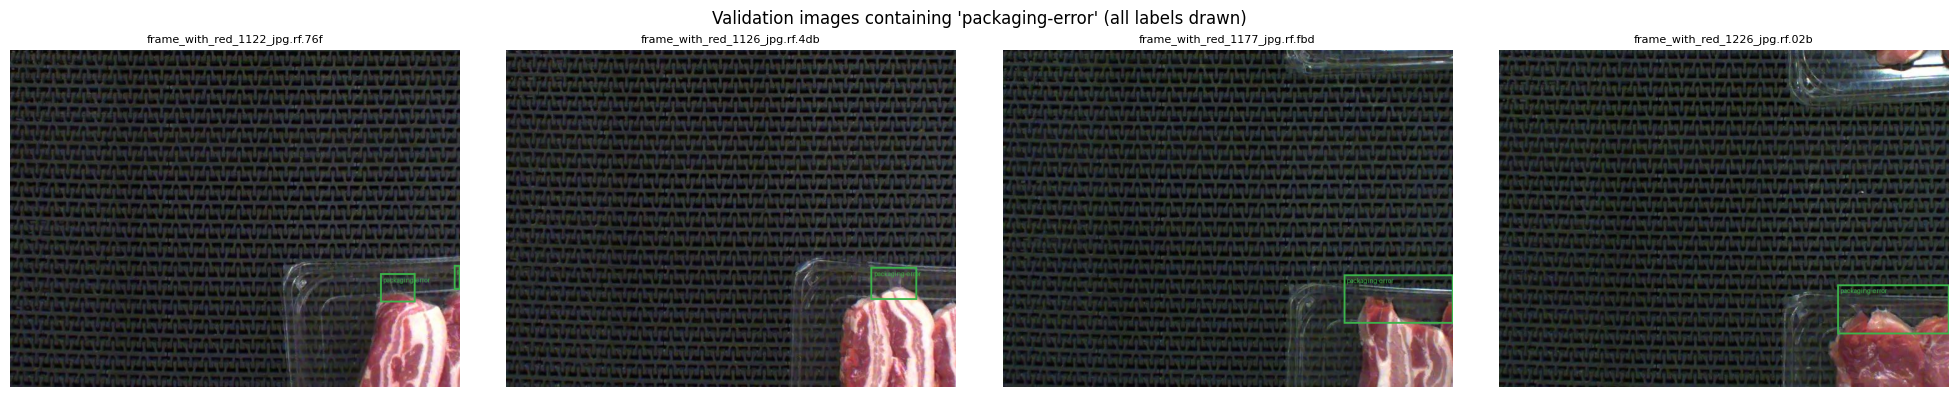

In [5]:
import matplotlib.pyplot as plt

target = "packaging-error" if "packaging-error" in CLASS_NAMES else CLASS_NAMES[0]
examples = pi.find_images_with_class(f"{DATA_DIR}/valid", CLASS_NAMES.index(target), limit=4)
if not examples:
    print(f"No validation images contain '{target}'.")
else:
    fig, axes = plt.subplots(1, len(examples), figsize=(5 * len(examples), 4), squeeze=False)
    for ax, (image_path, label_path) in zip(axes[0], examples):
        ax.imshow(pi.draw_yolo_boxes(image_path, label_path, CLASS_NAMES))
        ax.set_title(image_path.name[:30], fontsize=8)
        ax.axis("off")
    fig.suptitle(f"Validation images containing '{target}' (all labels drawn)")
    fig.tight_layout()
    fig.savefig(RESULTS / "packaging_error_examples.png", dpi=120)
    plt.show()

## 5. Leakage check

The file names suggest the photos are frames from a video. Frames that are next to each other in a video look almost the same. If a test photo has a near-identical twin in the training set, the test score will look better than it really is.

This checks how close each test photo is (in frame number) to the nearest training photo.

Note: if the photos came from more than one video, the same frame number could belong to different videos. A high result here is a warning, not definite proof of a problem.

In [6]:
def frames_in(folder):
    """Frame numbers of all images in a folder (images without one are skipped)."""
    numbers = [pi.frame_number(path.name) for path in Path(folder).iterdir()]
    return [number for number in numbers if number is not None]


train_frames = frames_in(f"{DATA_DIR}/train/images")
test_frames = frames_in(f"{DATA_DIR}/test/images")
print(f"Frame numbers found: {len(train_frames)} training images, {len(test_frames)} test images")

if train_frames and test_frames:
    gaps = pi.nearest_frame_gaps(test_frames, train_frames)
    leakage = pd.Series(pi.leakage_summary(gaps), name="share of test images")
    leakage.to_csv(RESULTS / "leakage_check.csv")
    print(leakage.map("{:.0%}".format))
else:
    print("Couldn't read frame numbers from the file names, so this check was skipped.")

Frame numbers found: 3349 training images, 80 test images
within 0 frames       5%
within 1 frames      29%
within 5 frames      68%
within 30 frames    100%
Name: share of test images, dtype: object


## 6. Train both models

Both models start from weights already trained on a large general photo dataset called COCO, then get fine-tuned on the tray photos. This is called transfer learning - it is faster than starting from scratch and usually gives better results on a small dataset.

An epoch is one full pass through all the training photos. After each epoch the model is checked against the validation photos. If the validation score stops improving for 8 epochs in a row, training stops early to avoid overfitting.

This is the slow part - around 45 to 60 minutes for both models.

In [7]:
from ultralytics import YOLO

trained = {}
for role, weights in MODELS.items():
    print(f"\n===== Training the {role} model ({weights}) =====")
    model = YOLO(weights)
    start = time.perf_counter()
    model.train(
        data=str(DATA_YAML),
        epochs=EPOCHS,
        patience=PATIENCE,
        imgsz=IMG_SIZE,
        seed=SEED,
        deterministic=True,
        workers=2,
        project="/content/runs",
        name=f"train_{role}",
        exist_ok=True,
    )
    trained[role] = {
        "weights": str(model.trainer.best),
        "train dir": Path(model.trainer.save_dir),
        "train minutes": (time.perf_counter() - start) / 60,
    }
    print(f"{role} model trained in {trained[role]['train minutes']:.1f} minutes")

    # Keep the training curves and their data for the report.
    out = RESULTS / f"training_{role}"
    out.mkdir(exist_ok=True)
    for file in [*trained[role]["train dir"].glob("*.png"), trained[role]["train dir"] / "results.csv"]:
        if file.exists():
            shutil.copy(file, out / file.name)


===== Training the baseline model (yolov8n.pt) =====
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/data/data.yaml, degrees=0.0, deterministic=True, device=, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=15, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=train_baselin

### Training curves (main model)

The losses should go down and the accuracy (mAP) should go up, then level off. If the validation loss starts going up while training loss keeps going down, the model is overfitting - it is memorising the training photos rather than learning to generalise.

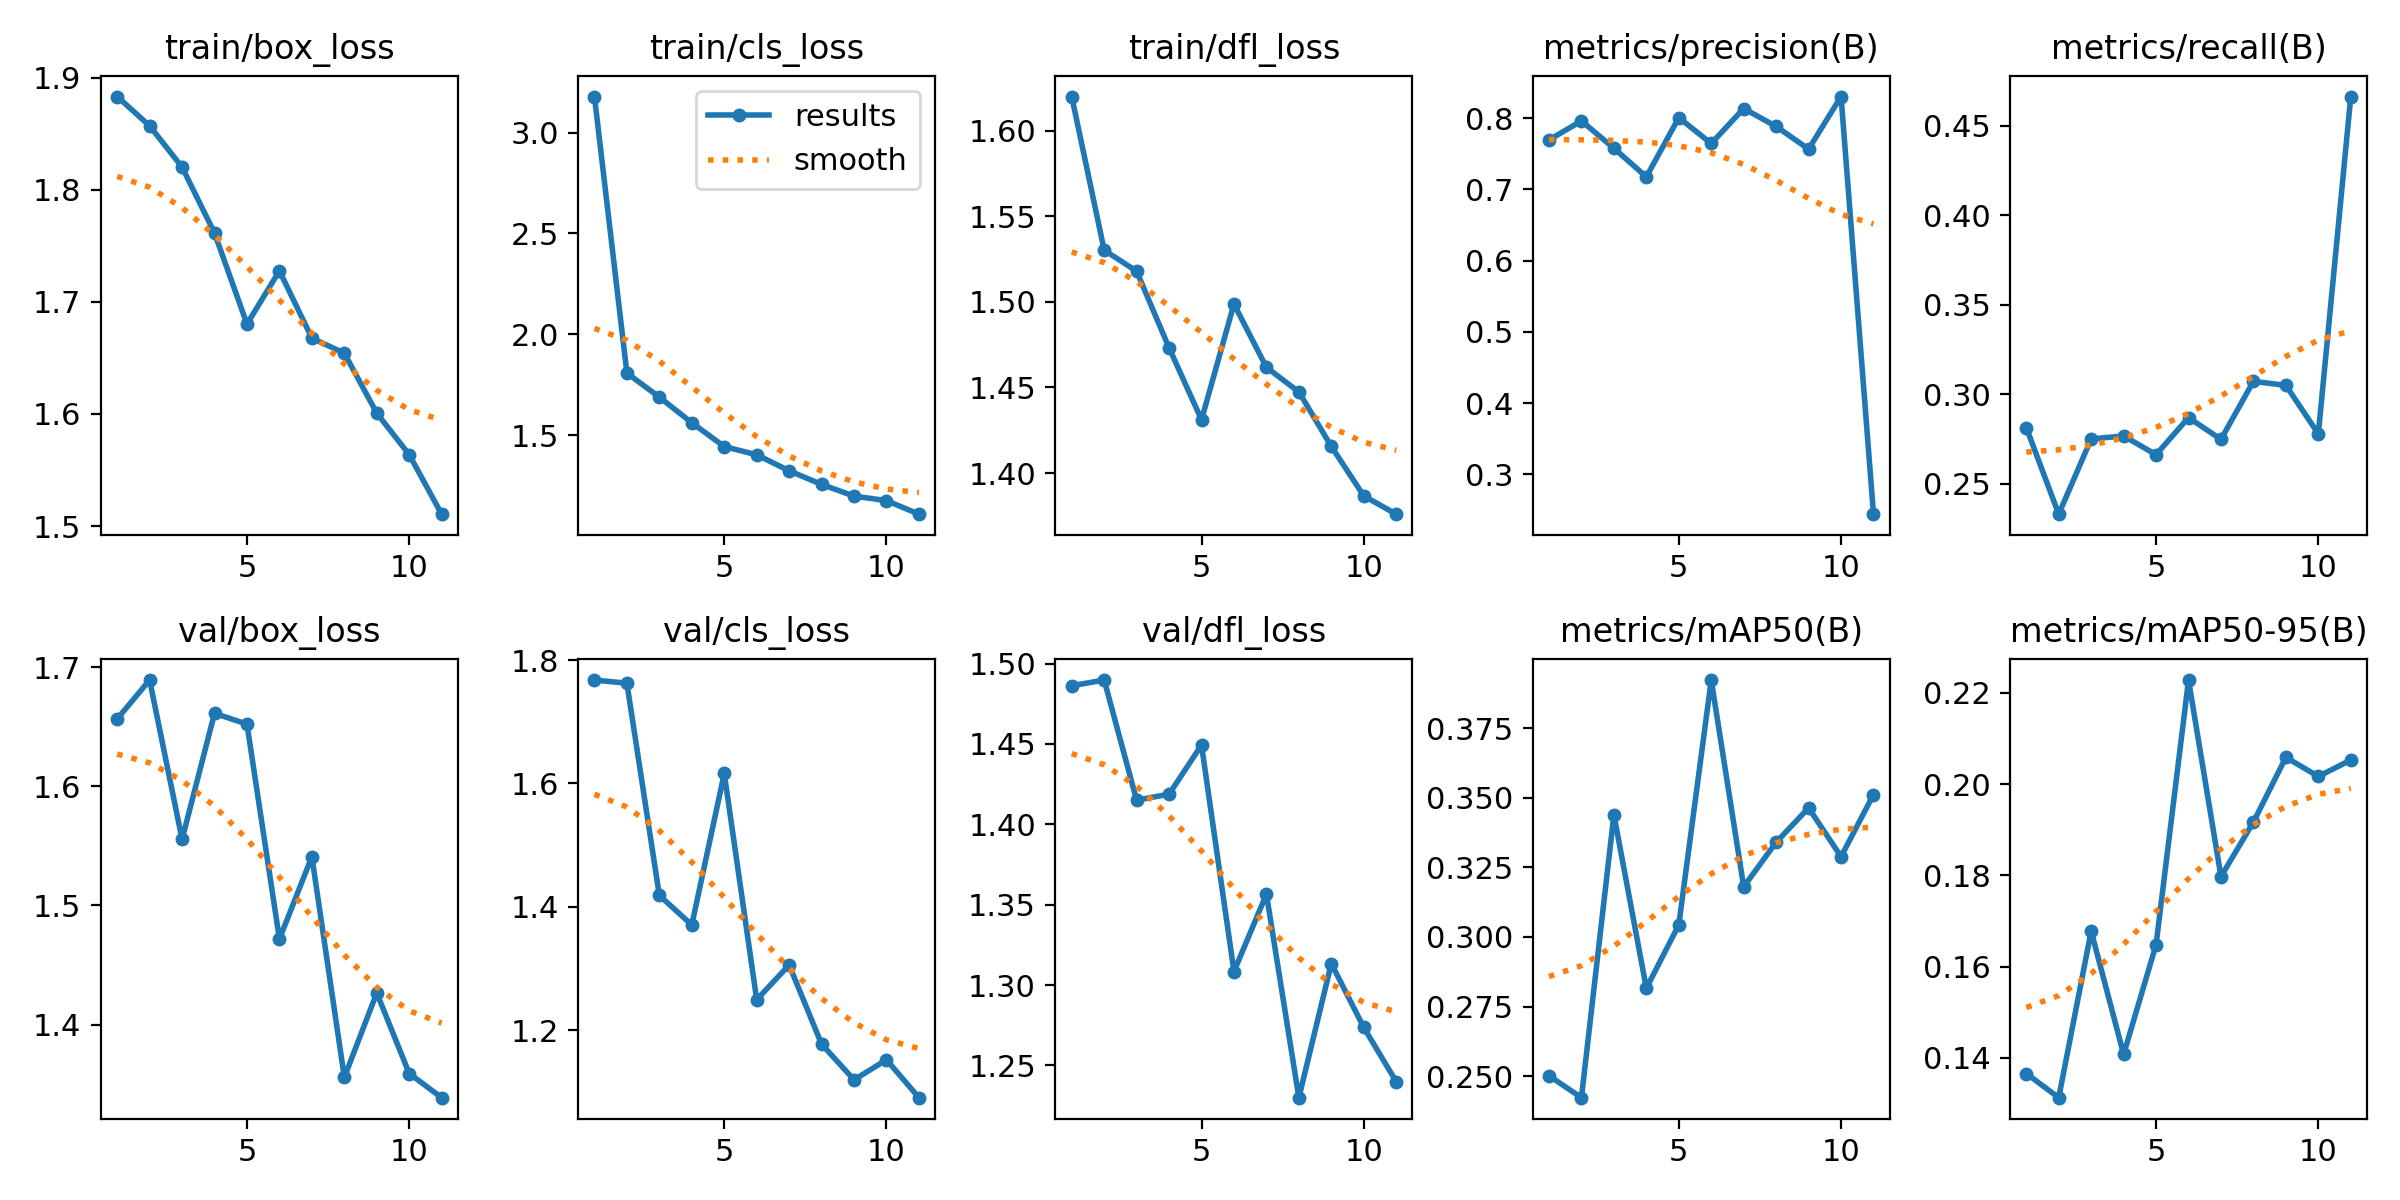

In [8]:
from IPython.display import Image as ShowImage, display

curves = RESULTS / "training_main" / "results.png"
if curves.exists():
    display(ShowImage(filename=str(curves), width=900))

## 7. Test both models

The test photos are used only once, here, after all decisions have already been made. Neither model was trained on or tuned using these photos.

**What the numbers mean**
- Precision: out of every defect the model flagged, how many were actually defects.
- Recall: out of every real defect in the photos, how many did the model find.
- mAP50: an overall accuracy score. A detection counts if its box overlaps the real box by at least 50%.
- mAP50-95: the same but averaged across stricter overlap thresholds up to 95%. It rewards more precise boxes.

Low recall on a production line means faulty trays reach customers. Low precision means good trays get flagged for re-checking. I discuss which matters more for this use case in my report.

In [9]:
summary = {}
class_rows = []
for role, info in trained.items():
    model = YOLO(info["weights"])
    _, n_params, _, gflops = model.info()  # prints a one-line summary of the model's size
    metrics = model.val(
        data=str(DATA_YAML),
        split="test",
        imgsz=IMG_SIZE,
        batch=16,
        project="/content/runs",
        name=f"test_{role}",
        exist_ok=True,
    )
    info["test dir"] = Path(f"/content/runs/test_{role}")
    summary[role] = {
        "model": f"{role} ({MODELS[role]})",
        "parameters (millions)": n_params / 1e6,
        "GFLOPs per image": gflops,
        "train minutes": info["train minutes"],
        **pi.summarise_test_metrics(metrics),
    }
    class_rows += [{"model": role, **row} for row in pi.per_class_table(metrics)]

    # Keep the test plots (confusion matrices, precision-recall curves) for the report.
    out = RESULTS / f"test_plots_{role}"
    out.mkdir(exist_ok=True)
    for png in info["test dir"].glob("*.png"):
        shutil.copy(png, out / png.name)

per_class = pd.DataFrame(class_rows)
per_class.to_csv(RESULTS / "per_class_results.csv", index=False)
per_class.round(3)

Model summary: 130 layers, 3,138,975 parameters, 0 gradients, 8.8 GFLOPs
Ultralytics 8.4.183 🚀 Python-3.13.15 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
Model summary (fused): 73 layers, 3,133,679 parameters, 0 gradients, 8.6 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 447.1±109.8 MB/s, size: 66.3 KB)
val: Scanning /content/data/test/labels... 80 images, 12 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 80/80 1.1Kit/s 0.1s
val: New cache created: /content/data/test/labels.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 5/5 2.2it/s 2.2s
                   all         80         79      0.342      0.392      0.367      0.195
            loose-meat          2          3      0.251      0.168      0.168     0.0838
       packaging-error         16         23      0.393      0.522      0.404       0.11
          twisted-meat          4          4          0          0     0.0288    0.00884
              unsealed  

,model,class,test boxes,precision,recall,mAP50,mAP50-95
0,baseline,loose-meat,3,0.251,0.168,0.168,0.084
1,baseline,packaging-error,23,0.393,0.522,0.404,0.110
2,baseline,twisted-meat,4,0.000,0.000,0.029,0.009
3,baseline,unsealed,49,0.722,0.878,0.870,0.576
4,main,loose-meat,3,1.000,0.000,0.013,0.003
5,main,packaging-error,23,0.375,0.304,0.289,0.093
6,main,twisted-meat,4,1.000,0.000,0.007,0.001
7,main,unsealed,49,0.783,0.816,0.830,0.506


### Confusion matrix (main model)

Shows what the model predicted vs what was actually there. Each row is a predicted class and each column is the real class. "background" means either the model missed a real defect or flagged something that wasn't a defect.

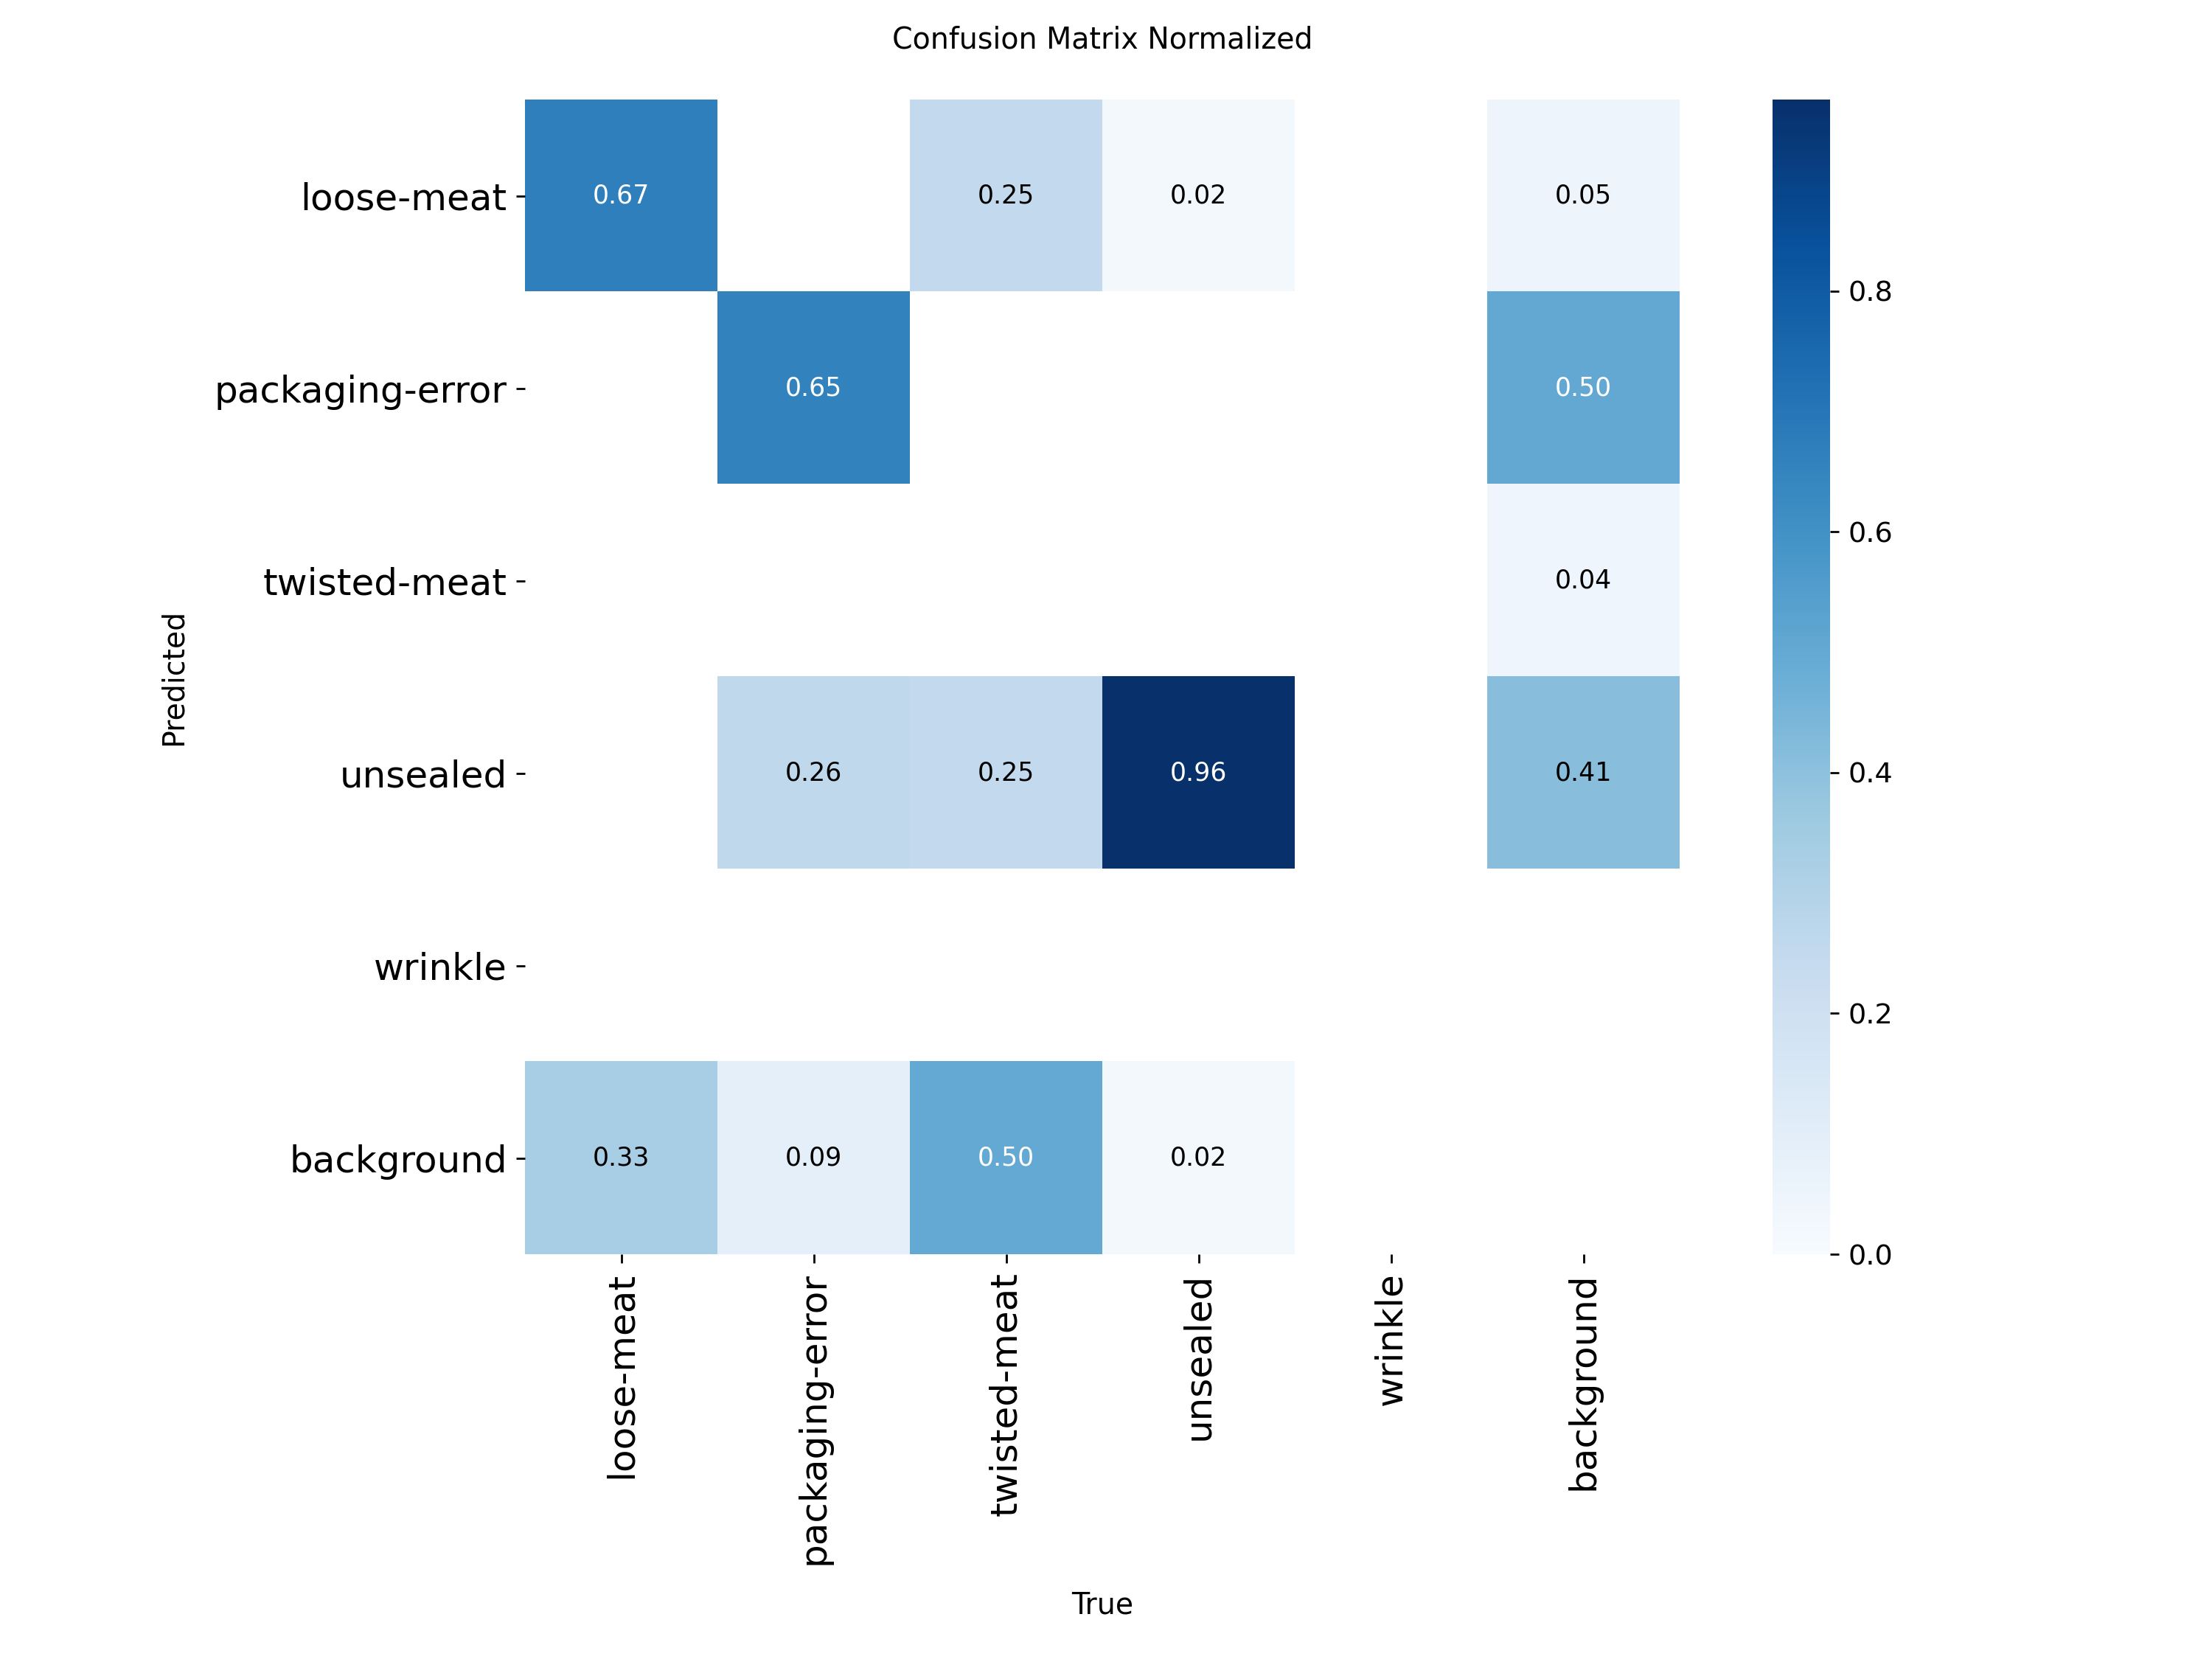

In [10]:
matrix = trained["main"]["test dir"] / "confusion_matrix_normalized.png"
if matrix.exists():
    display(ShowImage(filename=str(matrix), width=700))

## 8. Speed test

The testing above ran photos in batches of 16, which makes it look faster than it really is. On a real production line, photos arrive one at a time, so I time each photo individually on both GPU and CPU.

I use the median time rather than the average because occasional slow runs caused by background tasks would skew the average. One untimed warm-up run goes first because the first run always takes longer due to setup.

In [11]:
import statistics

test_images = sorted(
    path for path in Path(f"{DATA_DIR}/test/images").iterdir() if path.suffix.lower() in pi.IMAGE_EXTENSIONS
)[:N_TIMING_IMAGES]


def time_per_image(weights, device):
    """Median end-to-end time in milliseconds to process one image, plus every measurement."""
    model = YOLO(weights)
    model.predict(str(test_images[0]), imgsz=IMG_SIZE, device=device, verbose=False)  # warm-up, not timed
    times = []
    for image in test_images:
        start = time.perf_counter()
        model.predict(str(image), imgsz=IMG_SIZE, device=device, verbose=False)
        times.append((time.perf_counter() - start) * 1000)
    return statistics.median(times), times


timing_rows = []
for role, info in trained.items():
    for device, label in [(0, "GPU"), ("cpu", "CPU")]:
        median_ms, times = time_per_image(info["weights"], device)
        summary[role][f"{label} ms per tray (median)"] = median_ms
        summary[role][f"{label} trays per second"] = pi.images_per_second(median_ms)
        summary[role][f"{label} keeps up with {TRAYS_PER_MINUTE} trays/min?"] = pi.meets_line_speed(
            median_ms, TRAYS_PER_MINUTE
        )
        timing_rows += [{"model": role, "device": label, "ms": t} for t in times]

pd.DataFrame(timing_rows).to_csv(RESULTS / "latency_measurements_ms.csv", index=False)
comparison = pd.DataFrame(list(summary.values()))
comparison.to_csv(RESULTS / "model_comparison.csv", index=False)
comparison.set_index("model").T.round(3)

model,baseline (yolov8n.pt),main (yolov8s.pt)
parameters (millions),3.138975,11.137535
GFLOPs per image,8.754291,28.65065
train minutes,11.176988,9.066345
precision,0.341589,0.789498
recall,0.391701,0.280169
mAP50,0.367482,0.284829
mAP50-95,0.194522,0.150611
batched inference ms/image,5.136009,8.595012
GPU ms per tray (median),11.874098,15.571187
GPU trays per second,84.216923,64.22118


### Where does the time go?

A profiler records how long each part of the code takes. This runs the main model on 20 photos to see whether most of the time is spent on the actual model or on loading and preparing images.

In [12]:
import cProfile
import io
import pstats

model = YOLO(trained["main"]["weights"])
model.predict(str(test_images[0]), imgsz=IMG_SIZE, verbose=False)  # warm-up, not profiled
profiler = cProfile.Profile()
profiler.enable()
for image in test_images[:20]:
    model.predict(str(image), imgsz=IMG_SIZE, verbose=False)
profiler.disable()

report = io.StringIO()
pstats.Stats(profiler, stream=report).sort_stats("cumulative").print_stats(15)
(RESULTS / "profile_main_model.txt").write_text(report.getvalue())
print(report.getvalue())

         47603 function calls (38644 primitive calls) in 0.403 seconds

   Ordered by: cumulative time
   List reduced from 245 to 15 due to restriction <15>

   ncalls  tottime  percall  cumtime  percall filename:lineno(function)
       40    0.000    0.000    0.397    0.010 {method 'send' of 'generator' objects}
       40    0.001    0.000    0.397    0.010 /usr/local/lib/python3.13/dist-packages/ultralytics/engine/predictor.py:321(stream_inference)
      120    0.000    0.000    0.152    0.001 /usr/local/lib/python3.13/dist-packages/ultralytics/utils/ops.py:71(time)
      120    0.001    0.000    0.151    0.001 /usr/local/lib/python3.13/dist-packages/torch/cuda/__init__.py:1152(synchronize)
       60    0.000    0.000    0.150    0.003 /usr/local/lib/python3.13/dist-packages/ultralytics/utils/ops.py:62(__exit__)
      120    0.149    0.001    0.149    0.001 {built-in method torch._C._cuda_synchronize}
       20    0.000    0.000    0.144    0.007 /usr/local/lib/python3.13/dist-packa

## 9. Charts

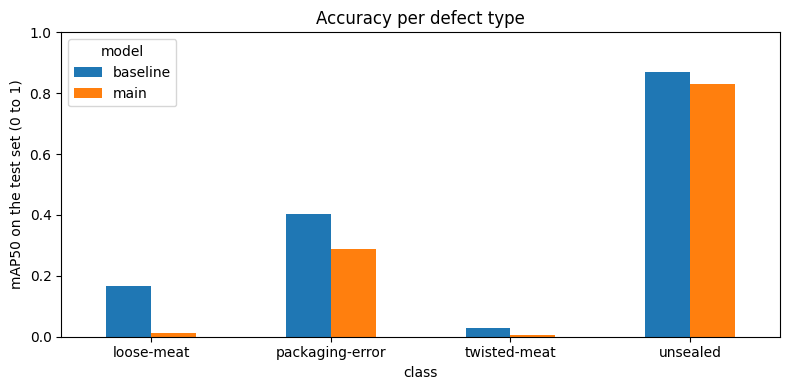

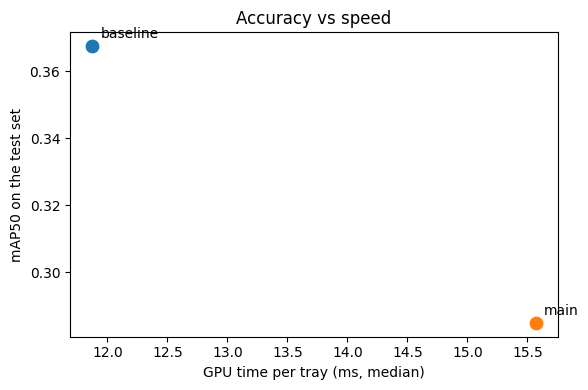

In [13]:
# Accuracy per defect type, both models side by side
ax = per_class.pivot(index="class", columns="model", values="mAP50").plot.bar(figsize=(8, 4), rot=0)
ax.set_ylabel("mAP50 on the test set (0 to 1)")
ax.set_ylim(0, 1)
ax.set_title("Accuracy per defect type")
plt.tight_layout()
plt.savefig(RESULTS / "per_class_map50.png", dpi=150)
plt.show()

# Accuracy against speed
fig, ax = plt.subplots(figsize=(6, 4))
for role, row in summary.items():
    point = (row["GPU ms per tray (median)"], row["mAP50"])
    ax.scatter(*point, s=80)
    ax.annotate(role, point, textcoords="offset points", xytext=(6, 6))
ax.set_xlabel("GPU time per tray (ms, median)")
ax.set_ylabel("mAP50 on the test set")
ax.set_title("Accuracy vs speed")
plt.tight_layout()
plt.savefig(RESULTS / "accuracy_vs_speed.png", dpi=150)
plt.show()

### Example predictions (main model)

Shows what the model actually detected on a few test photos. I look for missed defects, false alarms, and boxes in the wrong place - useful for the limitations section of my report.

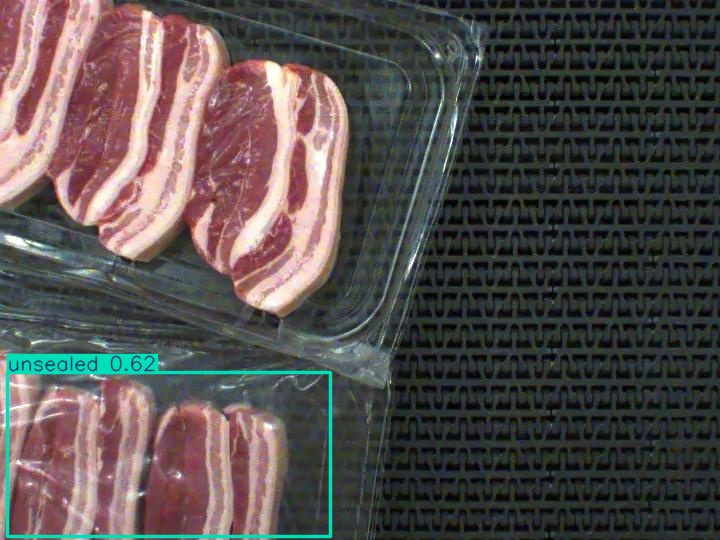

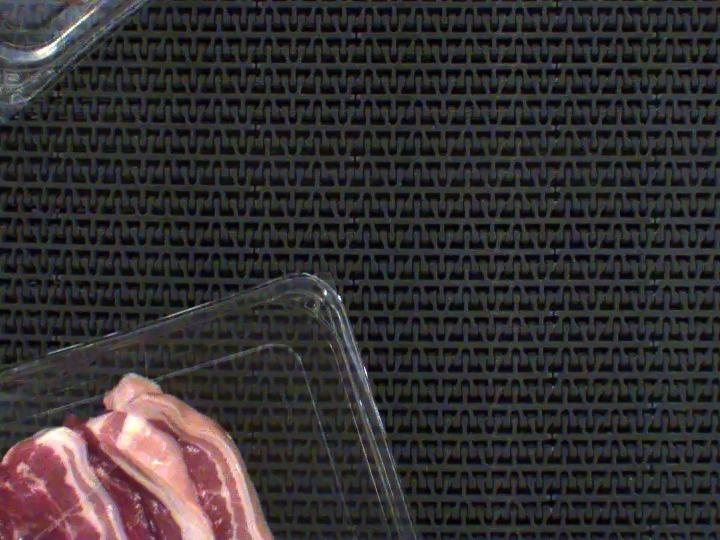

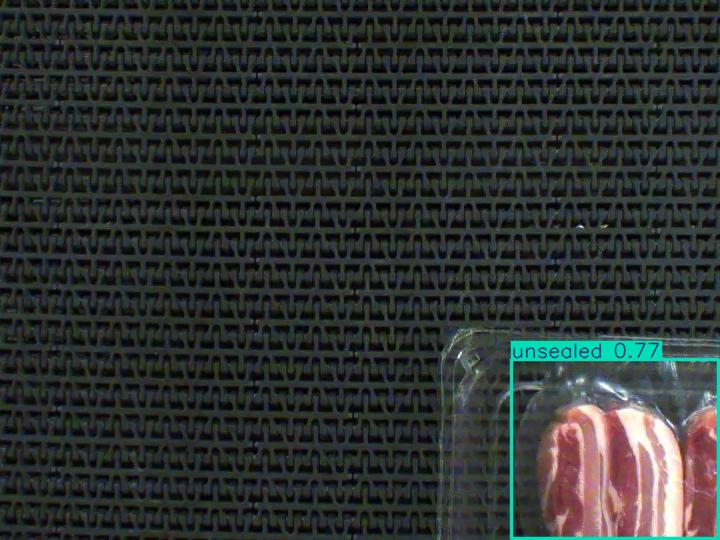

In [14]:
example_dir = RESULTS / "example_predictions"
example_dir.mkdir(exist_ok=True)
model = YOLO(trained["main"]["weights"])
for result in model.predict([str(path) for path in test_images[:6]], imgsz=IMG_SIZE, verbose=False):
    result.save(filename=str(example_dir / Path(result.path).name))

for path in sorted(example_dir.iterdir())[:3]:
    display(ShowImage(filename=str(path), width=600))

## 10. Tests and documentation

Runs the 41 tests for the helper functions and saves the results. Also builds the HTML documentation from the docstrings using pdoc.

In [15]:
tests = subprocess.run(
    [sys.executable, "-m", "pytest", "-v", "tests/"], cwd=CODE_DIR, capture_output=True, text=True
)
(DOCS / "test_report.txt").write_text(tests.stdout + tests.stderr)
print(tests.stdout[-3000:])

subprocess.run([sys.executable, "-m", "pdoc", "src/pork_inspect.py", "-o", "docs/html"], cwd=CODE_DIR, check=True)
print("HTML documentation saved to docs/html")

ect.py::test_parse_label_line_rejects_bad_input[3 0.5 0.4 0.2 0.1 0.9] PASSED [ 24%]
tests/test_pork_inspect.py::test_parse_label_line_rejects_bad_input[5 0.5 0.5 0.1 0.1] PASSED [ 26%]
tests/test_pork_inspect.py::test_parse_label_line_rejects_bad_input[-1 0.5 0.5 0.1 0.1] PASSED [ 29%]
tests/test_pork_inspect.py::test_parse_label_line_rejects_bad_input[1.5 0.5 0.5 0.1 0.1] PASSED [ 31%]
tests/test_pork_inspect.py::test_parse_label_line_rejects_bad_input[2 0.5 1.4 0.1 0.1] PASSED [ 34%]
tests/test_pork_inspect.py::test_parse_label_line_rejects_bad_input[2 0.5 abc 0.1 0.1] PASSED [ 36%]
tests/test_pork_inspect.py::test_count_labels_counts_boxes_empty_files_and_bad_lines PASSED [ 39%]
tests/test_pork_inspect.py::test_count_labels_missing_folder_raises PASSED [ 41%]
tests/test_pork_inspect.py::test_find_images_with_class PASSED           [ 43%]
tests/test_pork_inspect.py::test_find_images_with_class_bad_limit_raises PASSED [ 46%]
tests/test_pork_inspect.py::test_draw_yolo_boxes_draws_on_b

## 11. Download results

This downloads a zip of the results and docs folders. Then:

1. Unzip it on your computer.
2. On your GitHub repo: Add file, then Upload files.
3. Drag in the results and docs folders and commit.
4. Save this notebook with its outputs: File, Save a copy in GitHub, pick your repo, set the file path to notebooks/pork_rasher_defects.ipynb, then OK.

In [16]:
from google.colab import files

staging = Path("/content/upload_to_github")
shutil.rmtree(staging, ignore_errors=True)
for folder in ["results", "docs"]:
    shutil.copytree(CODE_DIR / folder, staging / folder)
files.download(shutil.make_archive(str(staging), "zip", staging))

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 12. Moodle submission zip

Only run this after everything is on GitHub. Change MAKE_MOODLE_ZIP to True and run the cell. It downloads a fresh copy of your whole repo including commit history, zipped up for submission.

If you are in a new Colab session, run the Settings cell first.

In [17]:
import shutil
import subprocess
from pathlib import Path

from google.colab import files

MAKE_MOODLE_ZIP = False  # change to True when everything is on GitHub

if MAKE_MOODLE_ZIP:
    clone_root = Path("/content/moodle_clone")
    shutil.rmtree(clone_root, ignore_errors=True)
    subprocess.run(
        ["git", "clone", f"https://github.com/{GITHUB_USER}/{REPO_NAME}.git", str(clone_root / REPO_NAME)],
        check=True,
    )
    files.download(shutil.make_archive(f"/content/{REPO_NAME}_clone", "zip", clone_root))
else:
    print("Skipped. Set MAKE_MOODLE_ZIP = True when you're ready.")

Skipped. Set MAKE_MOODLE_ZIP = True when you're ready.


## Where each output file goes in the report

| File (in results/ unless noted) | Report section |
|---|---|
| label_counts.csv, packaging_error_examples.png | Inputs, outputs and data |
| training_*/results.png | Computational approach |
| per_class_results.csv, per_class_map50.png, test_plots_*/ | Validation results |
| example_predictions/ | Validation: where it works and where it fails |
| leakage_check.csv | Validation: limitations of the test |
| model_comparison.csv, accuracy_vs_speed.png | Alternative solutions and performance |
| latency_measurements_ms.csv, profile_main_model.txt | Performance analysis |
| docs/test_report.txt, docs/html/ | Testing and documentation |